# Lecture 27: Sample Means and the Central Limit Theorem
v.ekc

Friday you discovered the CLT by experiment; today we pin down its three claims (shape, center, spread) and quantify exactly how sample size impacts the accuracy of the distribution of sample means.

**Today's sections:**
1. The distribution of the sample average
2. Center
3. Spread
4. Quantifying the effect of sample size

In [57]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

---
## 1. The Distribution of the Sample Average

Why is there a distribution at all? Because *every possible sample* has its own mean, and there are astronomically many samples (see below). We approximate the distribution by simulating 10,000 of them.

In [ ]:
united = Table.read_table('united.csv')
united_bins = np.arange(-20, 300, 10)
united.hist('Delay', bins=united_bins)
delay_mean = np.average(united.column('Delay'))
delay_sd = np.std(united.column('Delay'))
delay_mean,delay_sd

Friday's two helper functions:

In [59]:
def one_sample_mean(sample_size):
    """Take a sample from the population of flights and compute its mean"""
    sampled_flights = united.sample(sample_size)
    return np.mean(sampled_flights.column('Delay'))

In [60]:
def ten_thousand_sample_means(sample_size):
    """Sample from the population to approximate the distribution of the sample mean"""
    means = make_array()
    for i in np.arange(10000):
        mean = one_sample_mean(sample_size)
        means = np.append(means, mean)
    return means

Ten thousand means of size-100 samples, in one histogram:

In [ ]:
sample_means_100 = ten_thousand_sample_means(100)
Table().with_column('Mean of 100 flight delays', sample_means_100).hist(bins=20)

### Try It 1: Tiny samples

1. Use `ten_thousand_sample_means` to simulate 10,000 means of samples of size **10**, and draw their histogram. Try other sizes as well! When does it begin to look normally distributed?

2. Is it bell-shaped yet? How does it compare to the n=100 histogram above?

In [ ]:
# 1. 10,000 means of size-10 samples


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*At n = 10 the skew of the population still shows through; by n = 100 the bell shape has appeared!!*

```python
# 1.
sample_means_10 = ten_thousand_sample_means(10)
Table().with_column('Mean of 10 flight delays', sample_means_10).hist(bins=20)
```

*2. Still right-skewed with a long tail: ten flights are not enough for the CLT to smooth out those monster delays.*

</details>

---
## 2. CLT: Center

The distribution of sample means is centered at the **population average**.

In [ ]:
Table().with_column('Mean of 100 flight delays', sample_means_100).hist(bins=20)
print('Population Average:', delay_mean)
print('Average of sample means:', np.mean(sample_means_100))

### Try It 2: How close is the center? 😊

1. Compute the difference between the average of the 10,000 sample means and the population average. Is it big or small compared to the population SD (about 39.5)?
2. Try it for n=400! Use the function `ten_thousand_sample_means` to simulate 10,000 means of samples of size **400**, and draw their histogram. And then calculate the average of the 10,000 sample means with n=400

In [ ]:
# 1. difference between the two averages


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*The two averages agree to a small fraction of a minute, tiny next to a 39.5-minute SD. That is the center claim of the CLT.*

```python
# 1.
np.mean(sample_means_100) - delay_mean      # so smoll

#2.
sample_means_400 = ten_thousand_sample_means(400)
Table().with_column('Mean of 400 flight delays', sample_means_400).hist(bins=20)

print('Population Average:', delay_mean)
print('Average of sample means:', np.mean(sample_means_400))
```

</details>

---
## 3. CLT: Spread

**Task**: 
- Obtain ten thousand sample means, each being acquired from a sample size that we choose.
- Plot these on a histogram.
- Calculate/reference a few quantities of interest:
    - population standard deviation
    - standard deviation of the sample means
- See if we can pick up on pattern (how is sample size related to the standard deviation of the sample mean)!

In [61]:
def plot_sample_means(sample_size):
    """Empirical distribution of random sample means"""
    sample_means = ten_thousand_sample_means(sample_size)
    sample_means_tbl = Table().with_column('Sample Means', sample_means)
    
    # Print some information about the distribution of the sample means
    print("Population SD:", delay_sd)
    print("SD of sample means:", np.std(sample_means))
    print("Population SD / SD of sample means:",delay_sd/ np.std(sample_means))
    # Plot a histogram of the sample means
    sample_means_tbl.hist(bins=20)
    plots.xlabel('Sample Means')

Run this so the comparison plot below works:

In [62]:
# run me: needed below
sample_means_400 = ten_thousand_sample_means(400)
sample_means_900 = ten_thousand_sample_means(900)

Overlay the size-400 and size-900 distributions in one plot:

In [ ]:
means_tbl = Table().with_columns(
    '400', sample_means_400,
    '900', sample_means_900,
)

In [ ]:
means_tbl.hist(bins = np.arange(5, 31, 0.5))
plots.title('Distribution of Sample Average');

### Variability of Sample Average

In [ ]:
plot_sample_means(100)

In [ ]:
plot_sample_means(400)

In [ ]:
plot_sample_means(625)

#### The trend above we are seeing is...

$$\frac{\text{population SD}}{\text{SD of sample means}} = \sqrt{\text{sample size}}$$

#### Now, let's solve for the SD of the sample means...

$$\text{SD of sample means} = \frac{\text{population SD}}{\sqrt{\text{sample size}}}$$

---
## 4. Quantifying the Effect of Sample Size

Simulate the SD of sample means for many sample sizes and compare with the formula $\frac{\text{pop SD}}{ \sqrt{n}}$:

[14.5.1: The SD of All the Sample Means](https://inferentialthinking.com/chapters/14/5/variability-of-the-sample-mean/#the-sd-of-all-the-sample-means)

In [63]:
# Warning!!! This cell takes a long time to run! Don't run in class
sample_sizes = np.arange(100,950,50)

sample_mean_sds = make_array()
for n in sample_sizes:
    sample_means = ten_thousand_sample_means(n)
    sample_mean_sds = np.append(sample_mean_sds,np.std(sample_means)) 

Table the simulated SDs next to the formula's prediction:

In [64]:
sd_table = Table().with_columns(
'Sample size',sample_sizes,
'SD of simulated sample means', sample_mean_sds,
'Pop SD /sqrt(sample size)',delay_sd/np.sqrt(sample_sizes))
sd_table.show()

Sample size,SD of simulated sample means,Pop SD /sqrt(sample size)
100,3.92143,3.94802
150,3.25022,3.22354
200,2.7758,2.79167
250,2.51036,2.49695
300,2.27967,2.27939
350,2.10951,2.11031
400,1.98212,1.97401
450,1.87796,1.86111
500,1.77776,1.76561
550,1.68103,1.68344


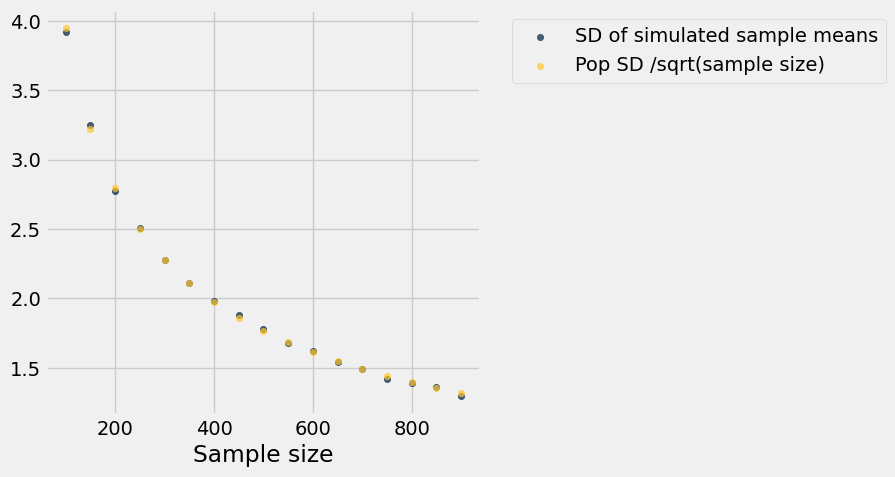

In [65]:
sd_table.scatter('Sample size')

> **The two sets of dots coincide.** The simulated SDs match $\frac{\text{pop SD}}{ \sqrt{n}}$ almost perfectly, the CLT's spread claim, confirmed. Quadrupling the sample size halves the spread:

In [ ]:
39.48 / np.sqrt(100)

In [ ]:
39.48 / np.sqrt(400)

And nine times the sample size cuts the spread to a third:

In [ ]:
39.48 / np.sqrt(900)

### Try It 3: Given a target accuracy....how big does the sample size have to be????

1. You want the SD of the sample mean to be at most **1 minute**. Using the formula, what sample size do you need?
$$\text{sample SD} = \frac{\text{pop SD}}{ \sqrt{n}}$$

3. Check your answer by plugging it back into the formula, or against `sd_table`.

In [ ]:
# 1. solve pop SD / sqrt(n) <= 1


In [ ]:
# 2. check


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Solve:*
- population SD =39.48
  $$\text{sample SD} = \frac{\text{pop SD}}{ \sqrt{n}} \quad\rightarrow \quad\frac{39.48}{ \sqrt{n}} \le 1$$ by squaring both sides.
  $$\frac{39.48^2}{ n} \le 1 \quad \rightarrow \quad n \ge 1558.6 \sim 1559$$
- n must be at least 39.48², about 1559 flights in order for the sample standard deviation to be at most 1.

```python
# 1.
delay_sd ** 2                       # about 1559, so n = 1559 flights

# 2.
delay_sd / np.sqrt(1559)            # just under 1 minute
```

We'll do this on Wednesday I think?
</details>

---
> **Today's takeaway:** sample means are normal, centered at the truth, with spread = $\frac{\text{pop SD}}{ \sqrt{n}}$. Accuracy costs quadratically: 2× the accuracy needs 4× the sample. Homework 8 runs on this arithmetic.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### The $\sqrt{n}$ law
```python
sd_of_sample_mean = pop_sd / np.sqrt(sample_size)
# 2x accuracy => 4x sample size
```